# Visual anomaly detection
This demo is based on the paper by Vitjan Zavrtanik, Matej Kristan and Danijel Skočaj: [*Reconstruction by inpainting for visual anomaly detection*](https://doi.org/10.1016/j.patcog.2020.107706), Pattern Recognition, 2021.

The images come from Amazon's [VisA](https://github.com/amazon-science/spot-diff) dataset (Yang Zou et al., [*SPot-the-Difference Self-Supervised Pre-training for Anomaly Detection and Segmentation*](https://arxiv.org/abs/2207.14315), ECCV 2022; CC BY 4.0 license), in [a reduced version](https://github.com/shuuchuu/datasets/tree/main/visa-subset): only the two objects the demo uses, a circuit board (`pcb4`) and a piece of chewing gum (`chewinggum`), as images 256 pixels high.

In [1]:
!rm -rf sample_data/
# VisA: the demo's two objects, in a reduced version (shuuchuu/datasets)
!wget -q https://github.com/shuuchuu/datasets/raw/refs/heads/main/ghsparse.sh -O /tmp/ghsparse.sh && bash /tmp/ghsparse.sh visa-subset
# The weights of a model already trained on the chewing gum (shuuchuu/models)
!wget -q -P RIAD_models https://github.com/shuuchuu/models/raw/refs/heads/main/riad-unet-visa/best_model_chewinggum.weights.h5

remote: Enumerating objects: 2, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 2 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (2/2), 2.71 KiB | 2.71 MiB/s, done.
remote: Enumerating objects: 1037, done.
remote: Counting objects: 100% (1037/1037), done.
remote: Compressing objects: 100% (1037/1037), done.
remote: Total 1037 (delta 0), reused 1037 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (1037/1037), 19.87 MiB | 32.19 MiB/s, done.
Updating files: 100% (1037/1037), done.
✓ visa-subset — 1037 fichiers, 23M


In [2]:
! nvidia-smi
! find visa-subset/*/train/ -name "*.jpg" | wc -l

Tue Oct 20 03:57:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.03             Driver Version: 580.159.03     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A4000               On  |   00000000:0A:00.0 Off |                  Off |
| 41%   47C    P8             18W /  120W |       1MiB /  16376MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from keras import layers
from PIL import Image
from sklearn.metrics import roc_auc_score
from tqdm.notebook import tqdm, trange

## Some useful functions

In [4]:
RESHAPE_DIM = (256, 256)


def load_data(files):
  data = np.zeros((len(files), *RESHAPE_DIM, 3), dtype="float32")
  for i in trange(len(files)):
    with Image.open(files[i]) as im:
      data[i] = im.convert("RGB").resize(RESHAPE_DIM, Image.Resampling.BILINEAR)
  return tf.convert_to_tensor(data / 255)


def display(data, is_mask=True):
  shape = data.shape
  if is_mask:
    h, w = shape[0], shape[1]
    fig, ax = plt.subplots(h, w, dpi=150)
    for l in range(h):
      for c in range(w):
        ax[l, c].set_xticks([])
        ax[l, c].set_yticks([])
        ax[l, c].imshow(data[l, c], cmap="gray")
  else:
    h, w = shape[0], 1
    fig, ax = plt.subplots(h, w, dpi=150)
    for i, axi in enumerate(ax):
      axi.set_xticks([])
      axi.set_yticks([])
      axi.imshow(data[i], cmap="gray")

## List of objects


In [5]:
dossier_donnees = Path("visa-subset")
liste_objets = sorted(d.name for d in dossier_donnees.iterdir() if d.is_dir())
for obj in liste_objets:
  print(obj)

chewinggum
pcb4


## Retrieving data for an object
 * Training data
 * Test data including abnormal and valid cases
 * Anomaly detection masks

All data will be converted to 256 × 256 images.

In [6]:
objet = "pcb4"


def load_all(objet):
  # Training data
  files_train = sorted(
    list(Path(dossier_donnees, f"{objet}/train/good/").glob("*.jpg"))
  )
  data = load_data(files_train)

  # Defective data
  defect_path = set(Path(dossier_donnees, f"{objet}/test/").glob("*")) - set(
    Path(dossier_donnees, f"{objet}/test/").glob("good")
  )
  files_defect = set()
  for p in defect_path:
    files_defect = files_defect | set(p.glob("*.jpg"))
  files_defect = sorted(files_defect)
  defect_data = load_data(files_defect)

  # Valid data
  files_good = sorted(list(Path(dossier_donnees, f"{objet}/test/good/").glob("*.jpg")))
  goods = load_data(files_good)

  # Verification masks for defective data
  files_ground = sorted(
    list(Path(dossier_donnees, f"{objet}/ground_truth/").glob("*/*.png"))
  )
  ground = load_data(files_ground)
  return data, defect_data, goods, ground


data, defect_data, goods, ground = load_all(objet)

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

  0%|          | 0/101 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

## Image masking
The anomaly detection technique is based on the generation of masked image fragments.

To do this, $n$ masks are generated on a given image according to two rules:
* The image is randomly masked by blocks of $k\times k$ pixels (usually a power of two, but in theory a divisor of the image size)
* The masks have no masking intersection and hide the entire image if they are superimposed (1 pixel is masked by at most one mask, but at least one)

In [7]:
def generate_masks(images_shape: tuple, k: int = 2, n: int = 3) -> tf.Tensor:
  """images: batch of images
  k: size of hidding block
  n: number of masks
  """
  shape = (images_shape[0], *(ax // k for ax in images_shape[1:-1]))
  indices = tf.random.uniform(shape, minval=0, maxval=n, dtype=tf.dtypes.int32)
  masks = 1 - tf.one_hot(indices, n)
  masks = tf.image.resize(masks, images_shape[1:-1], method="area")
  return tf.einsum("bhwm->bmhw", masks)


def apply_masks(img: tf.Tensor, masks: tf.Tensor) -> tf.Tensor:
  masked_shape = (-1, 1, *(ax for ax in img.shape[1:]))
  masks_shape = (-1, *(ax for ax in masks.shape[1:]), 1)
  masked = tf.multiply(tf.reshape(masks, masks_shape), tf.reshape(img, masked_shape))
  return masked


def reconstruct_image(imgs: tf.Tensor, masks: tf.Tensor) -> tf.Tensor:
  masks_shape = (-1, *(ax for ax in masks.shape[1:]), 1)
  invert_masks = tf.reshape(1 - masks, masks_shape)
  if len(masks.shape) == 3:
    imgs_r = tf.math.reduce_sum(imgs * invert_masks, axis=0)
  else:
    imgs_r = tf.math.reduce_sum(imgs * invert_masks, axis=1)
  return imgs_r

`generate_masks` produces random masks for each image and `apply_masks` allows you to duplicate an image and apply the masks created on each of the copies.
To see the result, let's apply these methods to two images.

**You can change the size of the masks $k$ and the number of masks $n$**

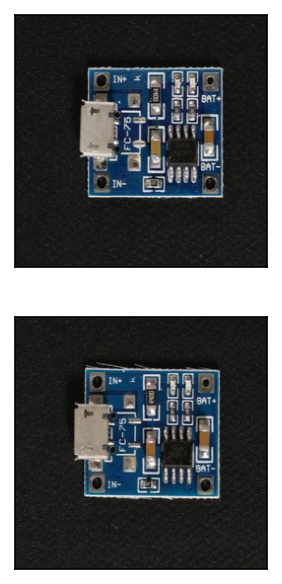

In [8]:
# Generate masks
masks = generate_masks(data[:2].shape, k=16, n=3)
# Apply masks
data_masked = apply_masks(data[:2], masks)

display(data[:2], is_mask=False)

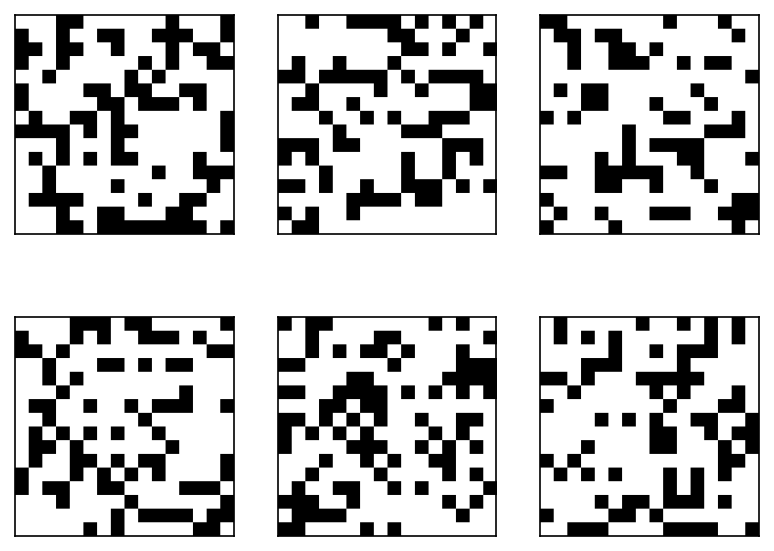

In [9]:
display(masks)

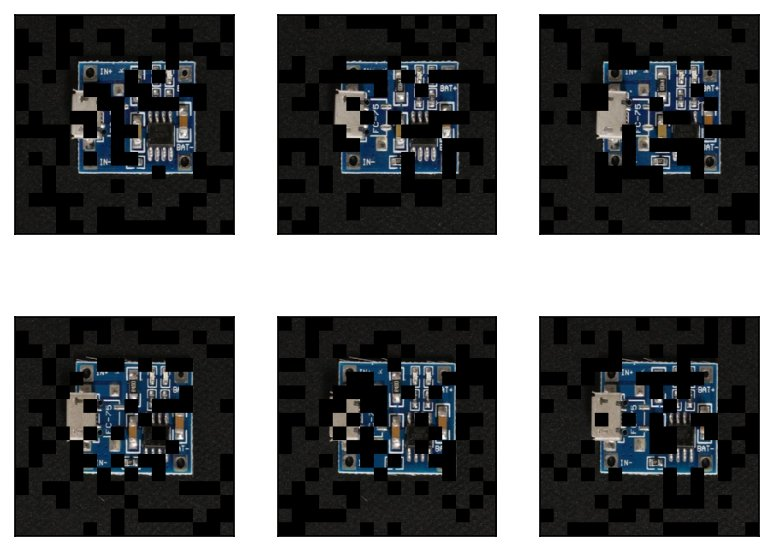

In [10]:
display(data_masked)

The masks are mutually exclusive, i.e. they never cover the same part of the image. The objective of the model will be to fill in the missing parts of the masked data and then reassemble them.

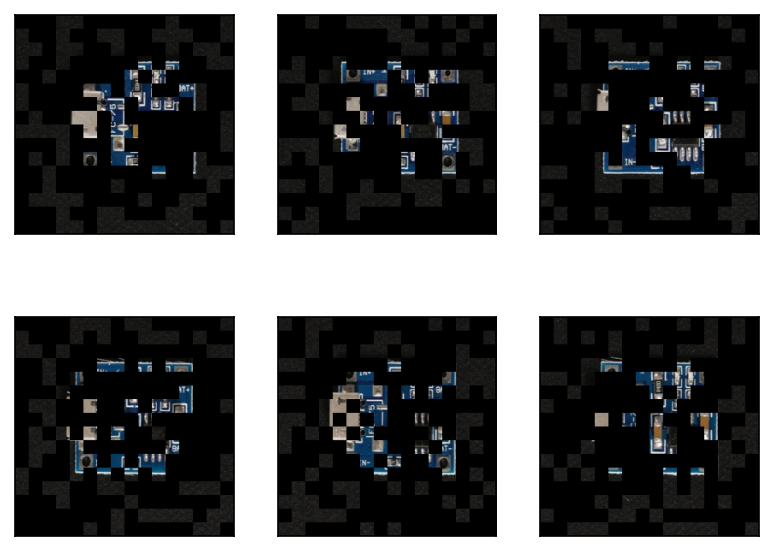

In [11]:
inverse_masked = apply_masks(data[:2], 1 - masks)
display(inverse_masked)

## Cost function


The cost function for the method is calculated from the *Gradient magnitude similarity* and the *Structural similarity index*.

### Gradient magnitude similarity (GMS)


GMS is based on the calculation of a gradient $g(I)$ on the considered images:

$$g(I)=\sqrt{(I*h_x)^2+(I*h_y)^2}$$

with $*$ the convolution operator, $I$ the image and the pair $h_x$ and $h_y$ Prewitt filters on the dimensions $x$ and $y$ corresponding in general to :

$h_x=\begin{bmatrix}
-1 & 0 & +1 \\
-1 & 0 & +1 \\
-1 & 0 & +1
\end{bmatrix}$ and $h_y=\begin{bmatrix}
-1 & -1 & -1 \\
0 & 0 & 0 \\
+1 & +1 & +1
\end{bmatrix}$

$g(I)$ is therefore the magnitude of the image's gradient: the Euclidean norm of the vector made of its horizontal ($I*h_x$) and vertical ($I*h_y$) derivatives.

In [12]:
# Vectorized
def prewitt_filter(img: tf.Tensor, c=1e-9) -> tf.Tensor:
  # Define kernel for x differences
  if len(img.shape) < 4:
    im = tf.reshape(img, (1,) + img.shape)
  else:
    im = img
  kx = tf.broadcast_to(
    tf.constant(
      [[-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0]], shape=(3, 3, 1, 1)
    ),
    (3, 3, 3, 1),
  )
  # Define kernel for y differences
  ky = tf.broadcast_to(
    tf.constant(
      [[-1.0, -1.0, -1.0], [0.0, 0.0, 0.0], [1.0, 1.0, 1.0]], shape=(3, 3, 1, 1)
    ),
    (3, 3, 3, 1),
  )
  # Perform x convolution
  img_prewittx = (
    tf.nn.depthwise_conv2d(im, kx, strides=[1, 1, 1, 1], padding="SAME") / 3
  )
  # Perform y convolution
  img_prewitty = (
    tf.nn.depthwise_conv2d(im, ky, strides=[1, 1, 1, 1], padding="SAME") / 3
  )

  gmm = tf.math.sqrt(img_prewittx * img_prewittx + img_prewitty * img_prewitty + c)

  if len(img.shape) < 4:
    gmm = tf.reshape(gmm, img.shape)
  return gmm

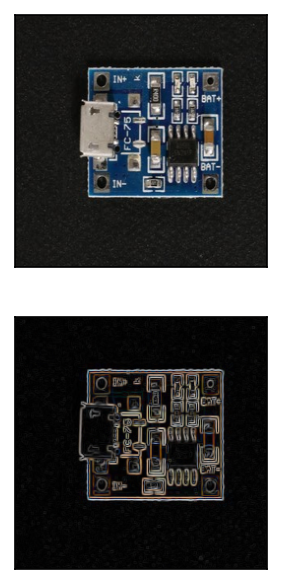

In [13]:
filtered_im = prewitt_filter(data[0])
display(tf.stack([data[0], filtered_im]), is_mask=False)

Using $g(I)$, we will compute the similarity metric GMS defined between two images $I$ and $I_r$ respectively the original image and the image reconstructed by the auto-encoder:

$GMS(I,I_r)= \frac{2g(I)g(I_r)+c}{g(I)^2+g(I_r)^2+c}$

with $c$ a constant allowing numerical stability.

In [14]:
# Vectorized.
def GMS(I: tf.Tensor, Ir: tf.Tensor, c=1e-9) -> tf.Tensor:
  gI = prewitt_filter(I)
  gIr = prewitt_filter(Ir)
  gms = (2 * gI * gIr + c) / (tf.math.square(gI) + tf.math.square(gIr) + c)
  return gms


# ones-tensor if same image
print(tf.math.reduce_mean(GMS(data[:2], data[:2]), axis=(-1, -2, -3)))
# non-ones-tensor if different
print(tf.math.reduce_mean(GMS(data[:2], data[2:4]), axis=(-1, -2, -3)))

tf.Tensor([1. 1.], shape=(2,), dtype=float32)
tf.Tensor([0.7078323 0.7256751], shape=(2,), dtype=float32)


### Cost function $L_G$

GMS gives one value per pixel (and per channel): the cost function $L_G$ is the mean of its complement to 1 over the whole image:

$$L_G(I,I_r)=\frac{1}{HW}\sum_{i=1}^H\sum_{j=1}^W \left(1 - GMS(I,I_r)_{i,j}\right)$$

with $H$ and $W$ the height and width of the image (the code also averages over the channels). It is 0 for two identical images.

In [15]:
# Vectorized. Take one image per argument
def L_G(I: tf.Tensor, Ir: tf.Tensor) -> tf.Tensor:
  if len(I.shape) < 4:
    return tf.math.reduce_mean(1 - GMS(I, Ir))
  return tf.math.reduce_mean(1 - GMS(I, Ir), axis=(-1, -2, -3))


# zeros-tensor if same image
print(L_G(data[:2], data[:2]))
# non-zero-tensor if different
print(L_G(data[:2], data[2:4]))

tf.Tensor([0. 0.], shape=(2,), dtype=float32)
tf.Tensor([0.2921677 0.274325 ], shape=(2,), dtype=float32)


Rather than using GMS, we will use its multiscale version $MSGMS(I,I_r)$. That is to say, voluntarily reduce the size of the images to be compared several times and apply GMS each time. The results are then averaged. This will notably allow to "smooth" the results.

In the original paper MSGMS is calculated with an average pooling of (2), up to one eighth of the initial size.

$$ MSGMS(I,I_r) = \frac{1}{|S|}\sum_{s\in S} GMS(I_s,I_{r,s})$$

with $S$ the set of reduced image sizes, $I_s$ and $I_{r,s}$ the images $I$ and $I_r$ resized to $s$

In [16]:
# Vectorized.
def MSGMS(I: tf.Tensor, Ir: tf.Tensor, is_loss=True) -> tf.Tensor:
  total_loss = GMS(I, Ir)

  for _ in range(3):
    I = tf.nn.avg_pool2d(I, 2, strides=2, padding="VALID")
    Ir = tf.nn.avg_pool2d(Ir, 2, strides=2, padding="VALID")
    total_loss += tf.image.resize(GMS(I, Ir), total_loss.shape[1:-1])

  total_loss = total_loss / 4
  if is_loss:
    return 1 - tf.reduce_mean(total_loss, axis=(-1, -2, -3))
  return total_loss


# vectorized version
print(MSGMS(data[:2], data[:2]))
print(MSGMS(data[:2], data[2:4]))

tf.Tensor([0. 0.], shape=(2,), dtype=float32)
tf.Tensor([0.25405914 0.21811575], shape=(2,), dtype=float32)


### Structural Similarity Index (SSIM)
SSIM is an image similarity measure defined by [Wang et al](https://www.cns.nyu.edu/pub/eero/wang03-reprint.pdf).

It takes into account 3 different criteria to establish similarity:
 * luminance
 * contrast
 * general structure

The method is already implemented in TensorFlow: [**tf.image.ssim**](https://www.tensorflow.org/api_docs/python/tf/image/ssim). We use the plain SSIM: its multiscale version (`tf.image.ssim_multiscale`) gives `NaN` gradients as soon as one of its intermediate scores is negative, which happens with the reconstructions of a network that has just started training. The SSIM gives one score per image, 1 for two identical images: as for the GMS, the cost function $L_S$ is its complement to 1:

$$L_S(I,I_r)=1 - \text{SSIM}(I,I_r)$$

In [17]:
# Vectorized.
def L_S(I: tf.Tensor, Ir: tf.Tensor, max_val=1.0) -> tf.Tensor:
  # Max val is the maximum difference between values allowed
  matrix_ssim = tf.image.ssim(I, Ir, max_val)
  return 1 - matrix_ssim


# zero if same
print(L_S(data[:2], data[:2]))
# non-zero otherwise
print(L_S(data[:2], data[2:4]))

tf.Tensor([0. 0.], shape=(2,), dtype=float32)
tf.Tensor([0.55061066 0.5501993 ], shape=(2,), dtype=float32)


### Final cost function
The cost function $L$ that we will use is the weighted sum of the cost functions $L_G$ and $L_S$, plus the reconstruction error:

$$L=\lambda_G L_G + \lambda_S L_S + L_2$$

where $\lambda_G,\lambda_S$ are the weights of the respective cost functions $L_G, L_S$, and $L_2$ the mean squared reconstruction error, pixel by pixel, between the image and its reconstruction. In the code, $L_G$ is computed on the multiscale version (MSGMS), and the loss is summed over the images of the batch.

In [18]:
def loss_vad(
  y: tf.Tensor, y_hat: tf.Tensor, lambda_G: float = 1, lambda_S: float = 1
) -> tf.Tensor:
  return tf.reduce_sum(
    lambda_G * MSGMS(y, y_hat)
    + lambda_S * L_S(y, y_hat)
    + tf.math.reduce_mean((y - y_hat) ** 2, axis=(-1, -2, -3))
  )


# zero if same
print(loss_vad(data[:2], data[:2]))
# non-zero otherwise
print(loss_vad(data[:2], data[2:4]))

tf.Tensor(0.0, shape=(), dtype=float32)
tf.Tensor(1.6214013, shape=(), dtype=float32)


## Creation of the model
The RIAD model applies the masking technique to find anomalies that may be present in an image.

During training, the following algorithm is applied:
 * Random selection of a block size $k$ for the masks, among 2, 4, 8 and 16 pixels (the four sizes the error map `map_error` then combines)
 * Random generation and application of masks to images
 * For each masked image, the auto-encoder tries to reproduce the initial image.
 * The masked parts generated by the auto-encoder are reassembled to form a single image which is then compared to the original image

This algorithm doesn't fit an ordinary `fit`, which applies the model once and compares its output to a target: the `RIAD` class therefore overrides the training step, `train_step` (Keras guide [*Customizing what happens in `fit()`*](https://keras.io/guides/custom_train_step_in_tensorflow/)).
 * The loss is computed in `train_step`: `compile` only gets the optimizer.
 * `keras.metrics.Mean` trackers average the losses over the epoch: these averages are what `fit` displays and what `EarlyStopping` and `ModelCheckpoint` monitor, not the value of the last batch.
 * `fit` keeps everything else: batches, epochs, callbacks.

In [19]:
class RIAD(keras.Model):
  def __init__(self, *args, **kwargs):
    super().__init__(*args, **kwargs)
    # Losses averaged over the epoch, which fit displays and callbacks monitor
    self.loss_tracker = keras.metrics.Mean(name="loss")
    self.loss_g_tracker = keras.metrics.Mean(name="loss_g")
    self.loss_s_tracker = keras.metrics.Mean(name="loss_s")
    self.l2_tracker = keras.metrics.Mean(name="l2")

  @property
  def metrics(self):
    # Keras resets the metrics of this list at the start of each epoch
    return [
      self.loss_tracker,
      self.loss_g_tracker,
      self.loss_s_tracker,
      self.l2_tracker,
    ]

  def train_step(self, data):
    # fit(data) with no target: data is the batch of images itself
    x = data
    # Block size 2**k among 2, 4, 8 and 16, as in map_error
    k = tf.random.uniform((), minval=1, maxval=5, dtype=tf.int32)
    masks = generate_masks(x.shape, 2**k, 3)
    nb_masks = masks.shape[1]
    masked = apply_masks(x, masks)

    partial_xs = []
    with tf.GradientTape() as tape:
      for i in range(nb_masks):
        partial_xs.append(self(masked[:, i], training=True))  # Forward pass

      x_r = reconstruct_image(tf.stack(partial_xs, axis=1), masks)
      loss = loss_vad(x, x_r)

    # Compute the gradients and update the weights
    gradients = tape.gradient(loss, self.trainable_variables)
    self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

    # Update the averages, and return their current values for display
    self.loss_tracker.update_state(loss)
    self.loss_g_tracker.update_state(MSGMS(x, x_r))
    self.loss_s_tracker.update_state(L_S(x, x_r))
    self.l2_tracker.update_state(tf.reduce_mean((x - x_r) ** 2))
    return {m.name: m.result() for m in self.metrics}

  def map_error(self, data):
    """Anomaly map of each image of the batch, from the MSGMS score."""
    mask_sizes = (2, 4, 8, 16)
    Ga = tf.zeros(data.shape)
    avg_filter = tf.ones((21, 21, 3, 1)) / (21 * 21 * 3)
    for k in mask_sizes:
      masks = generate_masks(data.shape, k, 3)
      nb_masks = masks.shape[1]
      masked = apply_masks(data, masks)

      partial_xs = []
      for i in range(nb_masks):
        partial_xs.append(self(masked[:, i], training=False))  # Forward pass

      x_r = reconstruct_image(tf.stack(partial_xs, axis=1), masks)
      Ga += 1 - MSGMS(data, x_r, False)
    Ga = Ga / len(mask_sizes)
    Ga = tf.nn.conv2d(Ga, avg_filter, strides=[1, 1, 1, 1], padding="SAME")
    return Ga

### U-Net network

In [20]:
def downsample(inputs):
  return layers.MaxPooling2D(pool_size=(2, 2))(inputs)


def upsample(inputs):
  return layers.UpSampling2D(size=(2, 2))(inputs)


def semiblock(inputs, feature_maps):
  conv = layers.Conv2D(feature_maps, 3, activation="relu", padding="same")(inputs)
  batch_norm = layers.BatchNormalization()(conv)
  relu = layers.ReLU()(batch_norm)
  return layers.Dropout(0.1)(relu)


def block(inputs, feature_maps):
  return semiblock(semiblock(inputs, feature_maps), feature_maps)


def concat(*tensors):
  return layers.Concatenate()(list(tensors))


def unet(pretrained_weights=None, input_size=(256, 256, 3), starting_depth=64, steps=5):
  inputs = keras.Input(shape=input_size)
  encodings = []
  depths = [min(512, starting_depth * 2**i) for i in range(steps)]
  for depth in depths:
    encodings.append(block(downsample(encodings[-1]) if encodings else inputs, depth))
  x = encodings[-1]
  for depth, encoding in zip(depths[-2::-1], encodings[-2::-1]):
    x = block(concat(encoding, upsample(x)), depth)
  outputs = layers.Conv2D(
    3, 1, activation="sigmoid", padding="same", kernel_initializer="he_normal"
  )(x)

  model = RIAD(inputs, outputs)
  if pretrained_weights:
    model.load_weights(pretrained_weights)
  return model


# Build the model
model = unet()

## Training
WARNING: The learning process can be very long.

You can go straight down to the `Viewing with pre-trained models` part if you just want to see the result.

In [21]:
callbacks = [
  keras.callbacks.EarlyStopping(monitor="loss", patience=20, restore_best_weights=True),
  keras.callbacks.ModelCheckpoint(
    "best_model.weights.h5",
    monitor="loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
  ),
]
# No loss: train_step computes the loss itself
# Without XLA: its compiler lacks the masks' "area" resize, on GPU
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), jit_compile=False)
history = model.fit(data, batch_size=5, epochs=1000, callbacks=callbacks)

Epoch 1/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 49s 659ms/step - l2: 0.1157 - loss: 5.6423 - loss_g: 0.2947 - loss_s: 0.7180
Epoch 2/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 34s 674ms/step - l2: 0.0905 - loss: 4.7990 - loss_g: 0.2433 - loss_s: 0.6260
Epoch 3/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 34s 687ms/step - l2: 0.0734 - loss: 4.3898 - loss_g: 0.2250 - loss_s: 0.5796
Epoch 4/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 35s 696ms/step - l2: 0.0541 - loss: 4.1116 - loss_g: 0.2144 - loss_s: 0.5538
Epoch 5/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 35s 701ms/step - l2: 0.0263 - loss: 3.5689 - loss_g: 0.1938 - loss_s: 0.4936
Epoch 6/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 35s 705ms/step - l2: 0.0081 - loss: 2.8523 - loss_g: 0.1775 - loss_s: 0.3848
Epoch 7/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 35s 710ms/step - l2: 0.0070 - loss: 2.5770 - loss_g: 0.1673 - loss_s: 0.3411
Epoch 8/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 36s 712ms/step - l2: 0.0069 - loss: 2.5251 - loss_g: 0.1674 - loss_s: 0.3307
Epoch 9/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 36s 714ms/step - l2: 0.0

## Evaluations
Let's look at the results of our learning, first on a few images, then on the whole test set (AUROC).

In [22]:
def error_vis(im, pred, err_map, ground=None, name=None):
  fig, ax = plt.subplots(
    len(im), 3 if ground is None else 4, figsize=(9, 4 * len(im)), squeeze=False
  )
  for j, title in enumerate(["Anomaly map", "Reconstruction", "Image", "Ground truth"]):
    if j < ax.shape[1]:
      ax[0, j].set_title(title)
  for i in range(len(im)):
    for axi in ax[i]:
      axi.set_xticklabels([])
      axi.set_yticklabels([])
    ax[i, 0].imshow(im[i])
    ax[i, 0].imshow(err_map[i][0, ..., 0], alpha=0.5, cmap="jet")

    ax[i, 1].imshow(pred[i])
    ax[i, 2].imshow(im[i])

    if ground is not None:
      ax[i, 3].imshow(im[i])
      ax[i, 3].imshow(ground[i], cmap="jet", alpha=0.3)
  fig.tight_layout()
  if name is not None:
    fig.savefig(f"{name}.png")
  else:
    plt.show()


def display_err(objet: str, max_object: int = 5, good_data=False):
  model = unet(f"RIAD_models/best_model_{objet}.weights.h5")
  _, defect_data, good, ground = load_all(objet)
  defect_data = defect_data[:max_object]
  ground = ground[:max_object]
  good = good[:max_object]
  errors = []
  if good_data:
    for d in tqdm(good):
      errors.append(model.map_error(d[tf.newaxis, :]))

    res = model.predict(good)
    error_vis(good, res, errors, name=objet)
  else:
    for d in tqdm(defect_data):
      errors.append(model.map_error(d[tf.newaxis, :]))

    res = model.predict(defect_data)
    error_vis(defect_data, res, errors, ground, name=objet)


def anomaly_maps(model, images, batch_size=10):
  """Anomaly maps (height, width) of every image, batch by batch."""
  maps = [
    model.map_error(images[i : i + batch_size])
    for i in trange(0, len(images), batch_size)
  ]
  return tf.concat(maps, axis=0).numpy()[..., 0]


def auroc(model, defect_data, goods, ground):
  """Image and pixel AUROC, over the images with and without anomalies."""
  maps = np.concatenate([anomaly_maps(model, defect_data), anomaly_maps(model, goods)])
  # Ground truth: 1 for an image (a pixel) with an anomaly, 0 otherwise
  image_labels = np.r_[np.ones(len(defect_data)), np.zeros(len(goods))]
  pixel_labels = np.concatenate(
    [ground.numpy()[..., 0] > 0.5, np.zeros((len(goods), *RESHAPE_DIM), dtype=bool)]
  )
  # Score of an image: the maximum of its anomaly map
  image_scores = maps.max(axis=(1, 2))
  print(f"Image AUROC: {roc_auc_score(image_labels, image_scores):.3f}")
  print(f"Pixel AUROC: {roc_auc_score(pixel_labels.ravel(), maps.ravel()):.3f}")

### Data with anomalies

In [23]:
# Only the first 10 images, for a readable figure
errors = []
for d in tqdm(defect_data[:10]):
  errors.append(model.map_error(d[tf.newaxis, :]))

res = model.predict(defect_data[:10])

  0%|          | 0/10 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


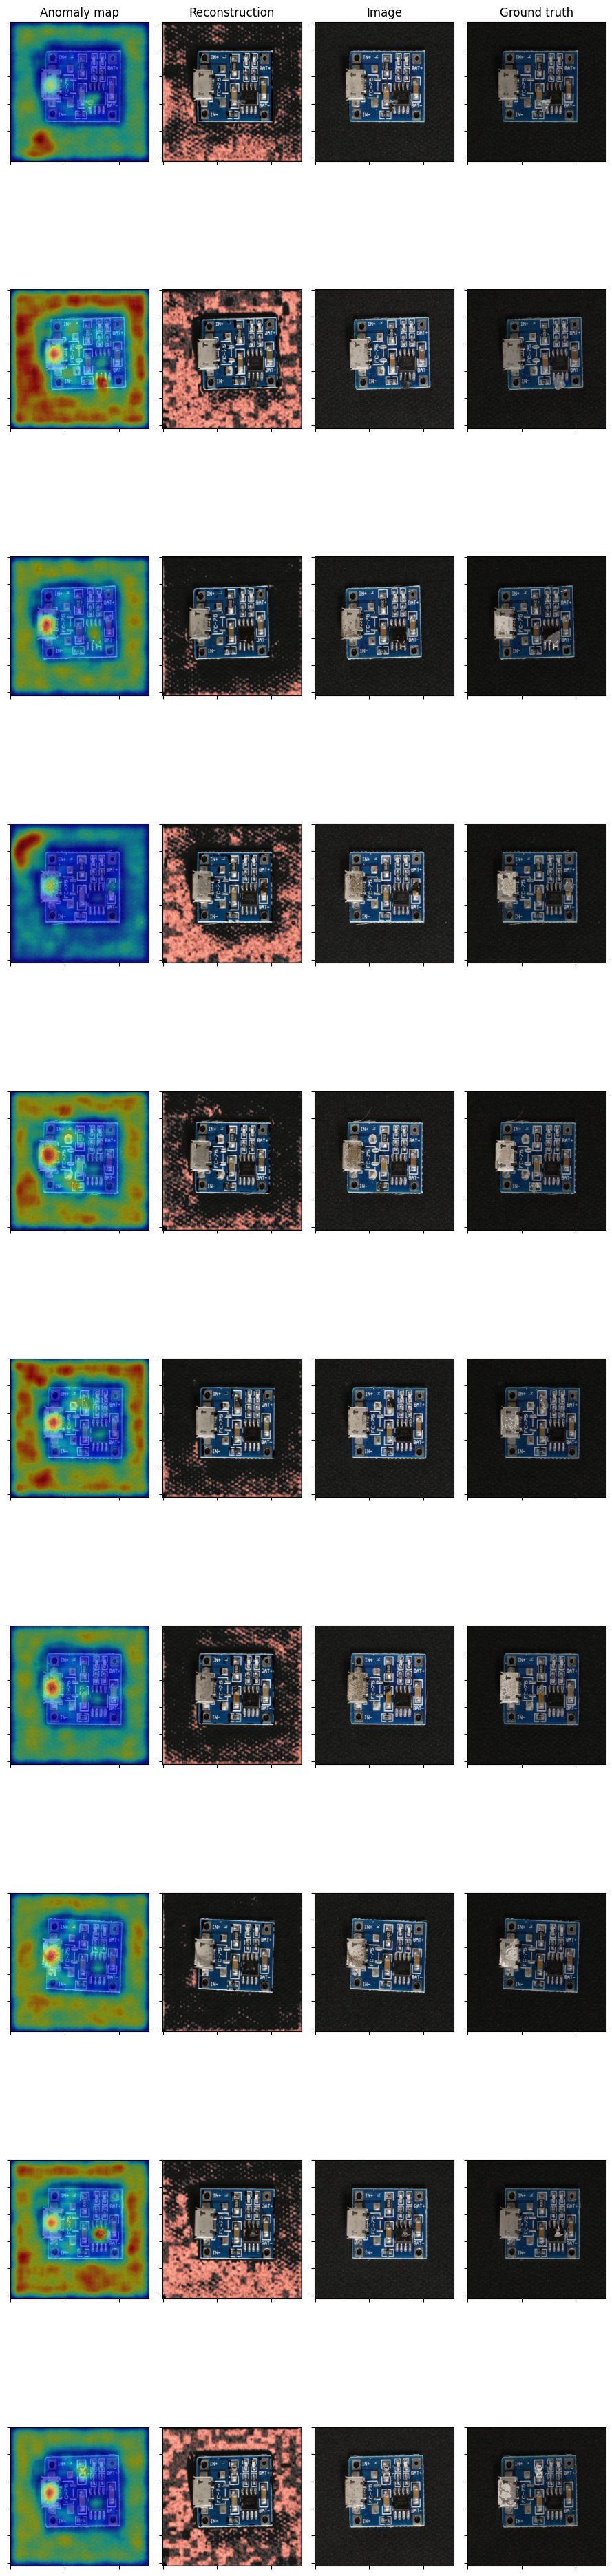

In [24]:
error_vis(defect_data[:10], res, errors, ground[:10])

### Data without anomaly

In [25]:
err_goods = []
for d in tqdm(goods[:10]):
  err_goods.append(model.map_error(d[tf.newaxis, :]))

res_goods = model.predict(goods[:10])

  0%|          | 0/10 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step


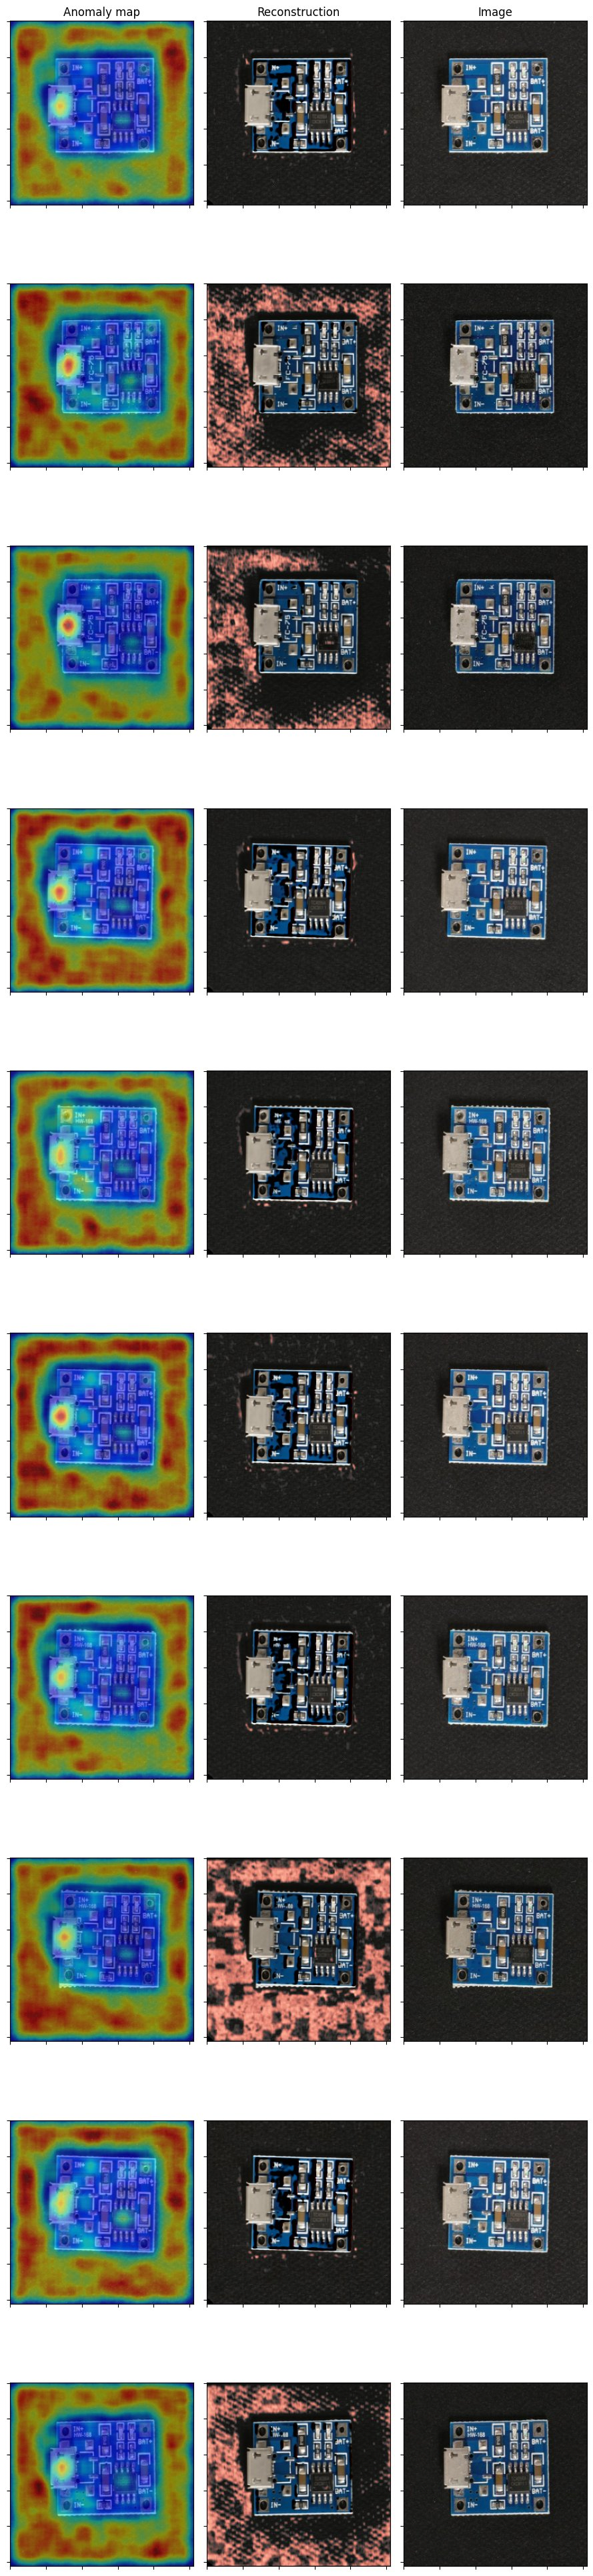

In [26]:
error_vis(goods[:10], res_goods, err_goods)

### Score on the whole test set
The figures only show a few images. To measure the detector on the whole test set, we compute the area under the ROC curve (AUROC), the metric of the benchmark datasets (MVTec AD, VisA) and of the anomalib library:
 * **per image**: an image's score is the maximum of its anomaly map, and the AUROC is the probability that an image with an anomaly gets a higher score than a normal image (0.5: chance; 1: perfect detector);
 * **per pixel**: each pixel is ranked by its value in the anomaly map, and compared to the ground truth mask (the pixels of normal images are all normal).

In [27]:
auroc(model, defect_data, goods, ground)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

Image AUROC: 0.848
Pixel AUROC: 0.680


## Visualisation with pre-trained models

### Data with anomalies

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


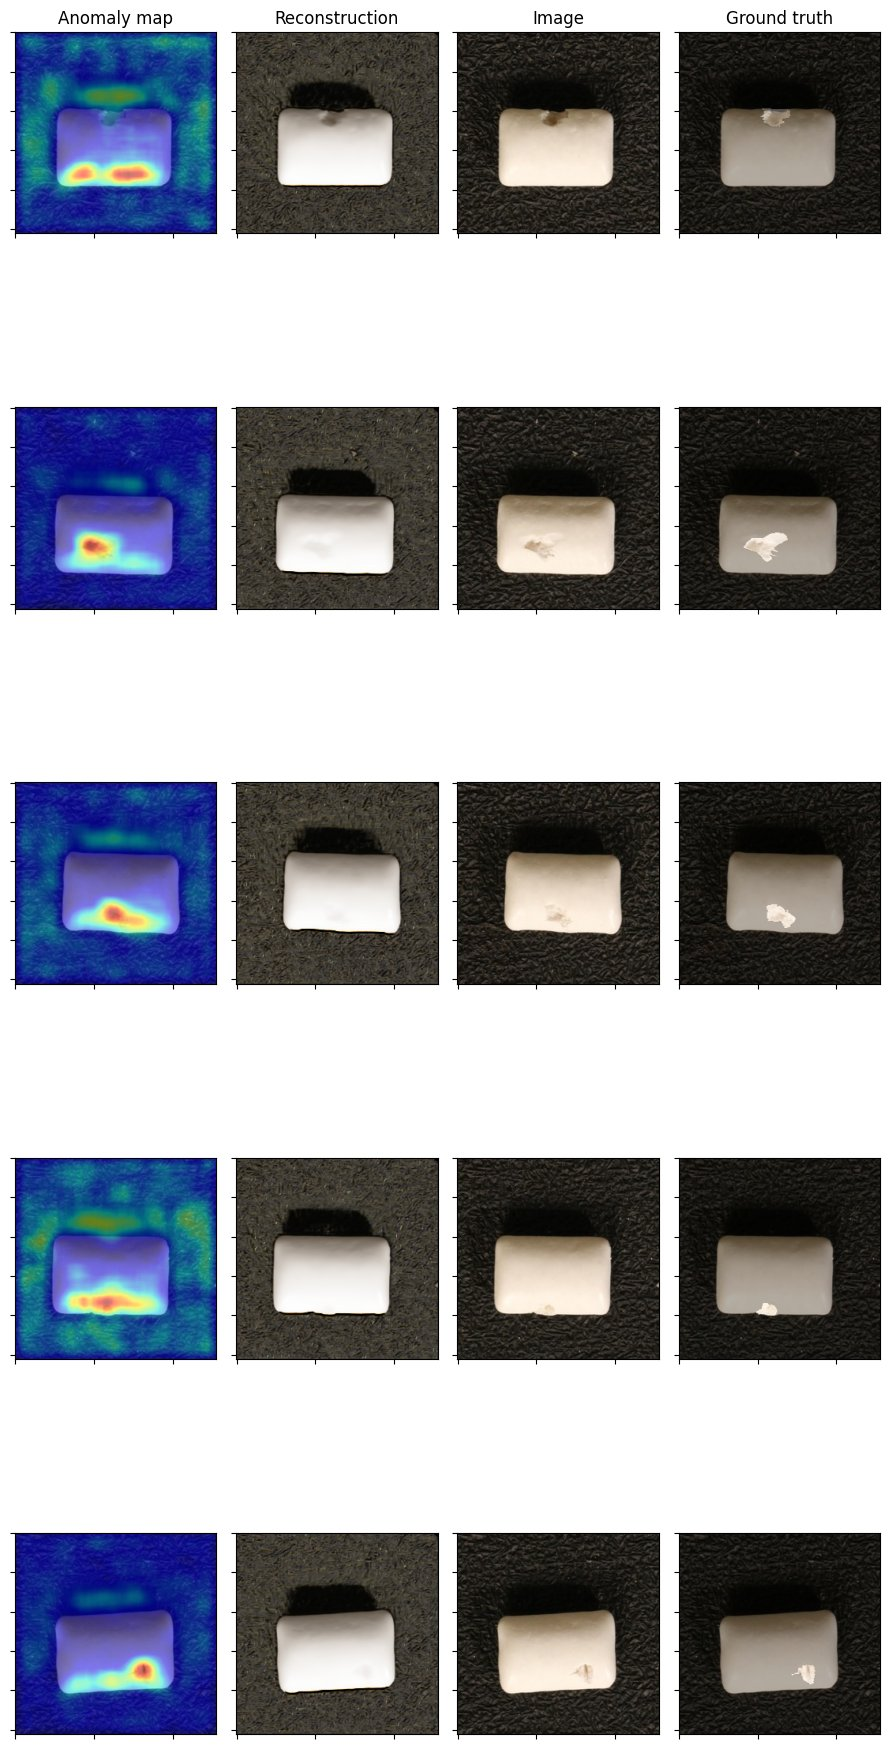

In [28]:
objet = "chewinggum"
display_err(objet)

### Data without anomaly


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


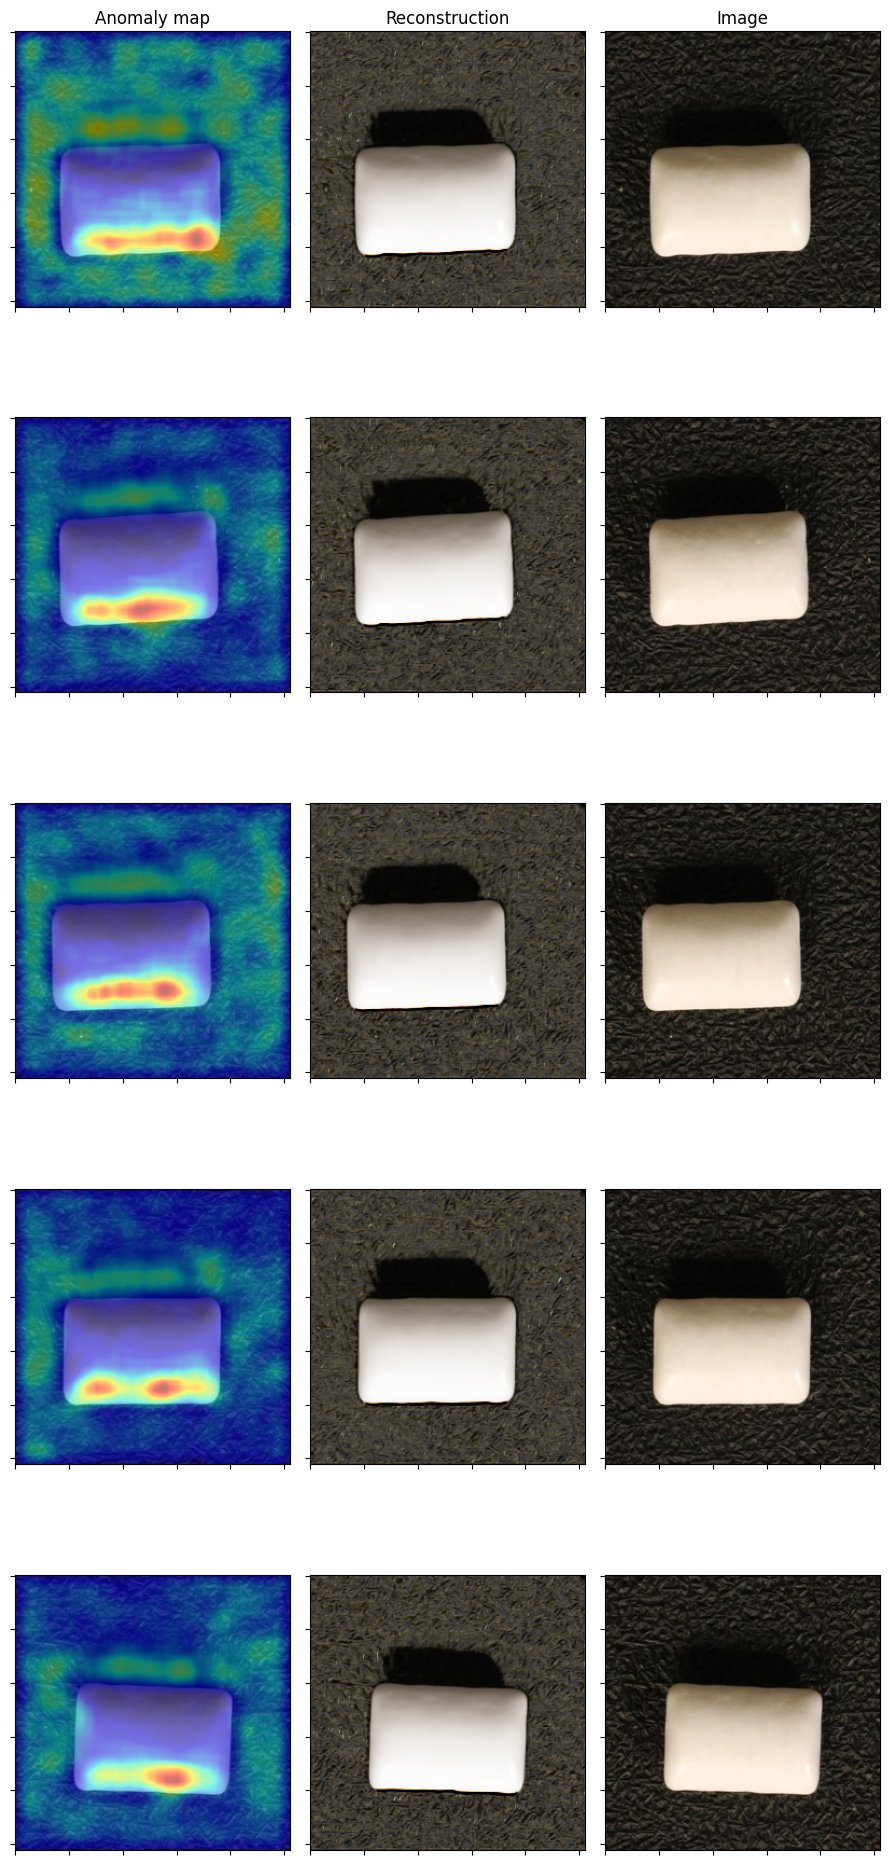

In [29]:
display_err(objet, good_data=True)

### Score of the pre-trained model
The same AUROC computation, on the whole chewing gum test set.

In [30]:
_, defect_data_gum, goods_gum, ground_gum = load_all(objet)
auroc(
  unet(f"RIAD_models/best_model_{objet}.weights.h5"),
  defect_data_gum,
  goods_gum,
  ground_gum,
)

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

Image AUROC: 0.753
Pixel AUROC: 0.859
